# C-MAPSS exploratory data analysis

Explores the NASA C-MAPSS turbofan data under `$HEPA_DATA_DIR/CMAPSS` (FD001-FD004),
first as raw files, then as HEPA sees it: 14 selected sensors, run-to-failure train
engines split by id, last cycle labelled as the event, and horizon labels
`time_to_event <= h` for `h = 1..150`.

Run with the `eda` dependency group: `uv run --group eda jupyter lab` (or select the
project `.venv` kernel in Cursor).

In [1]:
import os
from pathlib import Path

os.environ.setdefault("HEPA_DATA_DIR", "/Users/arto/data/HEPA")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.cluster import KMeans

from hepa.data.cmapss import COL_NAMES, SELECTED_SENSORS, load_cmapss
from hepa.training.finetune import EventDataset
from hepa.utils.config import get_context, get_horizons

DATA = Path(os.environ["HEPA_DATA_DIR"]) / "CMAPSS"
SUBSETS = ["FD001", "FD002", "FD003", "FD004"]
SENSORS = [f"s{i}" for i in range(1, 22)]
KEPT = [f"s{i}" for i in SELECTED_SENSORS]
DROPPED = [s for s in SENSORS if s not in KEPT]

pd.set_option("display.width", 160)
plt.rcParams["figure.dpi"] = 110
print(DATA)
print("kept:", KEPT)
print("dropped:", DROPPED)

/Users/arto/data/HEPA/CMAPSS
kept: ['s2', 's3', 's4', 's7', 's8', 's9', 's11', 's12', 's13', 's14', 's15', 's17', 's20', 's21']
dropped: ['s1', 's5', 's6', 's10', 's16', 's18', 's19']


## 1. Raw files

In [2]:
def read(kind: str, subset: str) -> pd.DataFrame:
    return pd.read_csv(
        DATA / f"{kind}_{subset}.txt", sep=r"\s+", header=None, names=COL_NAMES, index_col=False
    )


train = {s: read("train", s) for s in SUBSETS}
test = {s: read("test", s) for s in SUBSETS}
rul = {s: pd.read_csv(DATA / f"RUL_{s}.txt", header=None)[0].to_numpy() for s in SUBSETS}

for s in SUBSETS:
    lt = train[s].groupby("engine_id")["cycle"].max()
    train[s]["rul"] = train[s]["engine_id"].map(lt) - train[s]["cycle"]

train["FD001"].head()

,engine_id,cycle,op1,op2,op3,s1,s2,s3,s4,s5,...,s13,s14,s15,s16,s17,s18,s19,s20,s21,rul
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190,191
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236,190
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442,189
3,1,4,0.0007,0.0000,100.0,518.67,642.35,1582.79,1401.87,14.62,...,2388.08,8133.83,8.3682,0.03,392,2388,100.0,38.88,23.3739,188
4,1,5,-0.0019,-0.0002,100.0,518.67,642.37,1582.85,1406.22,14.62,...,2388.04,8133.80,8.4294,0.03,393,2388,100.0,38.90,23.4044,187


In [3]:
rows = []
for s in SUBSETS:
    life = train[s].groupby("engine_id")["cycle"].max()
    test_len = test[s].groupby("engine_id")["cycle"].max()
    rows.append({
        "subset": s,
        "train_engines": life.size,
        "train_rows": len(train[s]),
        "life_min": life.min(),
        "life_median": life.median(),
        "life_max": life.max(),
        "test_engines": test_len.size,
        "test_len_median": test_len.median(),
        "test_true_RUL_median": np.median(rul[s]),
        "op_conditions": train[s][["op1", "op2", "op3"]].round(0).drop_duplicates().shape[0],
    })
summary = pd.DataFrame(rows).set_index("subset")
summary

,train_engines,train_rows,life_min,life_median,life_max,test_engines,test_len_median,test_true_RUL_median,op_conditions
subset,,,,,,,,,
FD001,100,20631,128,199.0,362,100,133.5,86.0,1
FD002,260,53759,128,199.0,378,259,132.0,80.0,6
FD003,100,24720,145,220.5,525,100,148.0,77.5,1
FD004,249,61249,128,234.0,543,248,153.5,88.0,6


FD001/FD003 run at one operating condition, FD002/FD004 at six. FD001/FD002 have one
fault mode (HPC degradation), FD003/FD004 two (HPC + fan). The `test_*` files are
truncated before failure and are **not** used by HEPA's loader; it splits the
run-to-failure `train_*` engines instead.

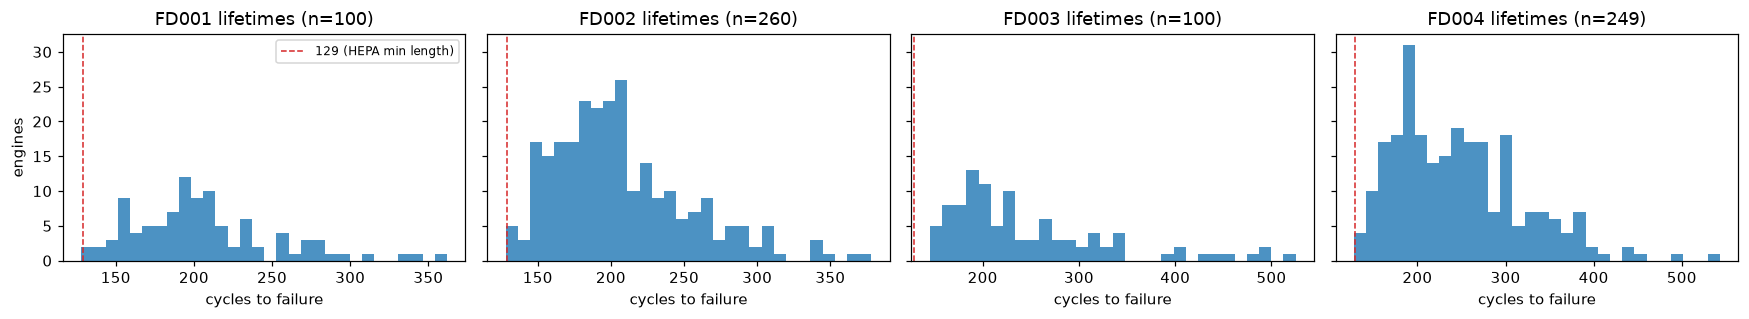

In [4]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3), sharey=True)
for ax, s in zip(axes, SUBSETS):
    life = train[s].groupby("engine_id")["cycle"].max()
    ax.hist(life, bins=30, color="tab:blue", alpha=0.8)
    ax.axvline(129, color="tab:red", ls="--", lw=1, label="129 (HEPA min length)")
    ax.set_title(f"{s} lifetimes (n={life.size})")
    ax.set_xlabel("cycles to failure")
axes[0].set_ylabel("engines")
axes[0].legend(fontsize=8)
plt.tight_layout()

## 2. Operating conditions

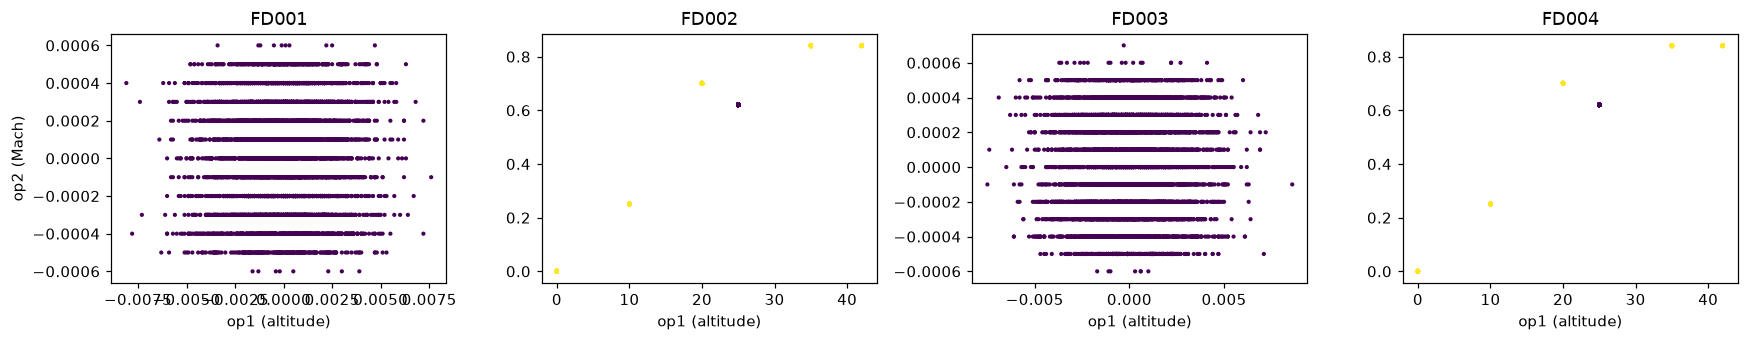

In [5]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.2))
for ax, s in zip(axes, SUBSETS):
    d = train[s].sample(min(5000, len(train[s])), random_state=0)
    ax.scatter(d["op1"], d["op2"], c=d["op3"], s=3, cmap="viridis")
    ax.set_title(s)
    ax.set_xlabel("op1 (altitude)")
axes[0].set_ylabel("op2 (Mach)")
plt.tight_layout()

## 3. Sensor variability: which sensors carry signal?

In [6]:
std = pd.DataFrame({s: train[s][SENSORS].std() for s in SUBSETS})
std["kept"] = std.index.isin(KEPT)
std.style.format("{:.4f}", subset=SUBSETS).background_gradient(subset=SUBSETS, axis=0)

,FD001,FD002,FD003,FD004,kept
s1,0.0000,26.3897,0.0000,26.4368,False
s2,0.5001,37.2894,0.5230,37.3426,True
s3,6.1311,105.9463,6.8104,106.1676,True
s4,9.0006,119.1234,9.7732,119.3276,True
s5,0.0000,3.6138,0.0000,3.6229,False
s6,0.0014,5.4318,0.0181,5.4440,False
s7,0.8851,146.0053,3.4373,146.8802,True
s8,0.0710,145.2098,0.1583,145.3482,True
s9,22.0829,335.8120,19.9803,336.9275,True
s10,0.0000,0.1275,0.0035,0.1277,False


In FD001/FD003 the seven dropped sensors are (near-)constant. In FD002/FD004 every
sensor varies, but mostly because of the operating regime, not degradation. The next
cell checks that by measuring the variance *within* each operating condition.

In [7]:
def add_condition(df: pd.DataFrame, k: int) -> pd.DataFrame:
    df = df.copy()
    df["cond"] = KMeans(n_clusters=k, n_init=10, random_state=0).fit_predict(
        df[["op1", "op2", "op3"]]
    )
    return df


for s in ["FD002", "FD004"]:
    train[s] = add_condition(train[s], 6)
for s in ["FD001", "FD003"]:
    train[s]["cond"] = 0

within = pd.DataFrame({
    s: train[s].groupby("cond")[SENSORS].std().mean() / train[s][SENSORS].std()
    for s in SUBSETS
})
within.round(3).T

,s1,s2,s3,s4,s5,s6,s7,s8,s9,s10,...,s12,s13,s14,s15,s16,s17,s18,s19,s20,s21
FD001,NaN,1.000,1.000,1.000,0.0,1.000,1.000,1.000,1.000,NaN,...,1.000,1.000,1.000,1.000,0.000,1.000,NaN,NaN,1.000,1.000
FD002,0.0,0.012,0.054,0.066,0.0,0.001,0.004,0.001,0.052,0.011,...,0.003,0.002,0.182,0.052,0.145,0.052,0.0,0.0,0.013,0.013
FD003,NaN,1.000,1.000,1.000,0.0,1.000,1.000,1.000,1.000,1.000,...,1.000,1.000,1.000,1.000,0.000,1.000,NaN,NaN,1.000,1.000
FD004,0.0,0.013,0.061,0.074,0.0,0.003,0.013,0.001,0.052,0.036,...,0.013,0.002,0.178,0.089,0.138,0.059,0.0,0.0,0.017,0.017


Ratio of mean within-condition std to overall std. Values far below 1 in FD002/FD004
mean the operating condition explains most of that sensor's variance.

## 4. Degradation trajectories

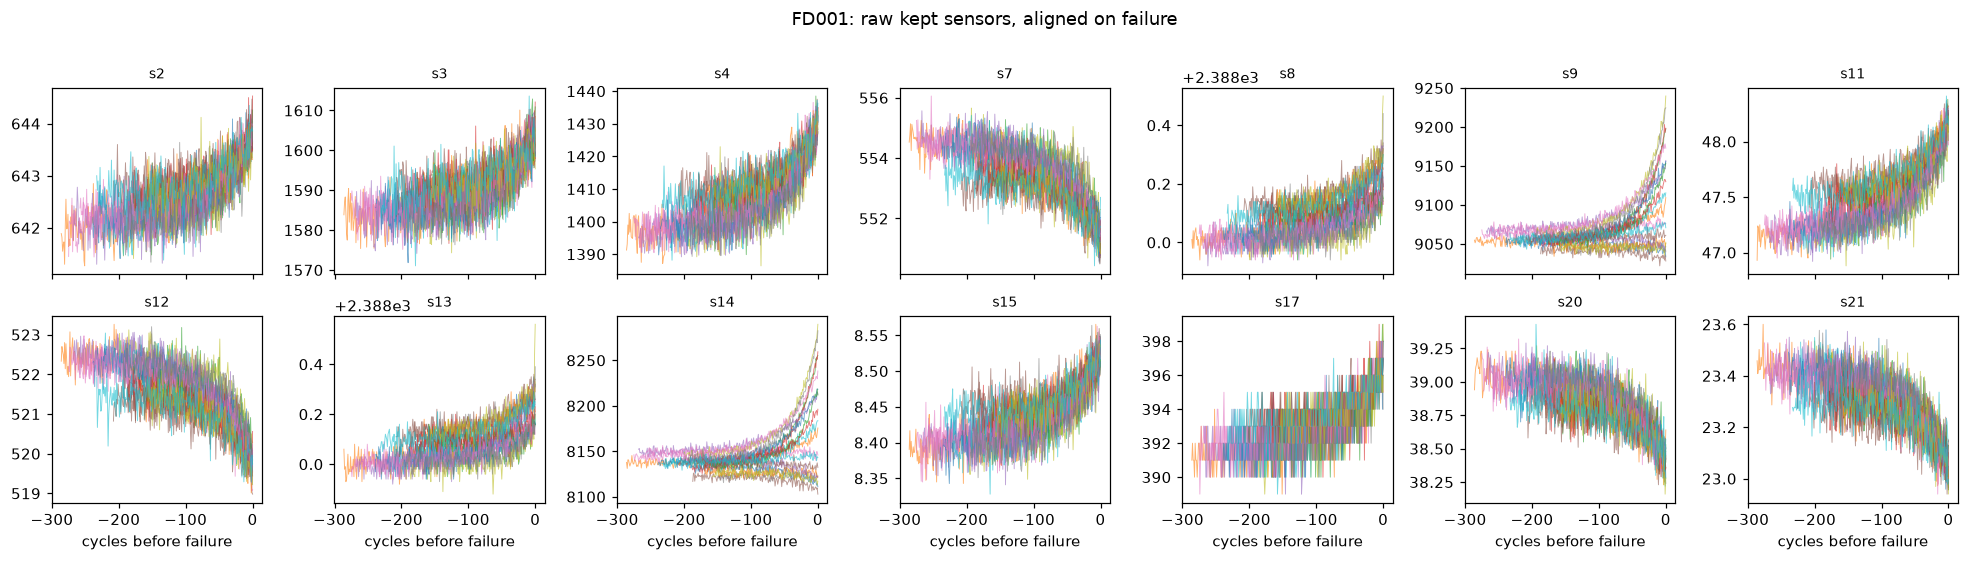

In [8]:
def plot_trajectories(s: str, df: pd.DataFrame, title: str, n_engines: int = 20) -> None:
    eids = df["engine_id"].unique()[:n_engines]
    fig, axes = plt.subplots(2, 7, figsize=(18, 5), sharex=True)
    for ax, sensor in zip(axes.flat, KEPT):
        for e in eids:
            g = df[df["engine_id"] == e]
            ax.plot(-g["rul"], g[sensor], lw=0.6, alpha=0.6)
        ax.set_title(sensor, fontsize=9)
    for ax in axes[1]:
        ax.set_xlabel("cycles before failure")
    fig.suptitle(f"{s}: {title}", y=1.01)
    plt.tight_layout()


plot_trajectories("FD001", train["FD001"], "raw kept sensors, aligned on failure")

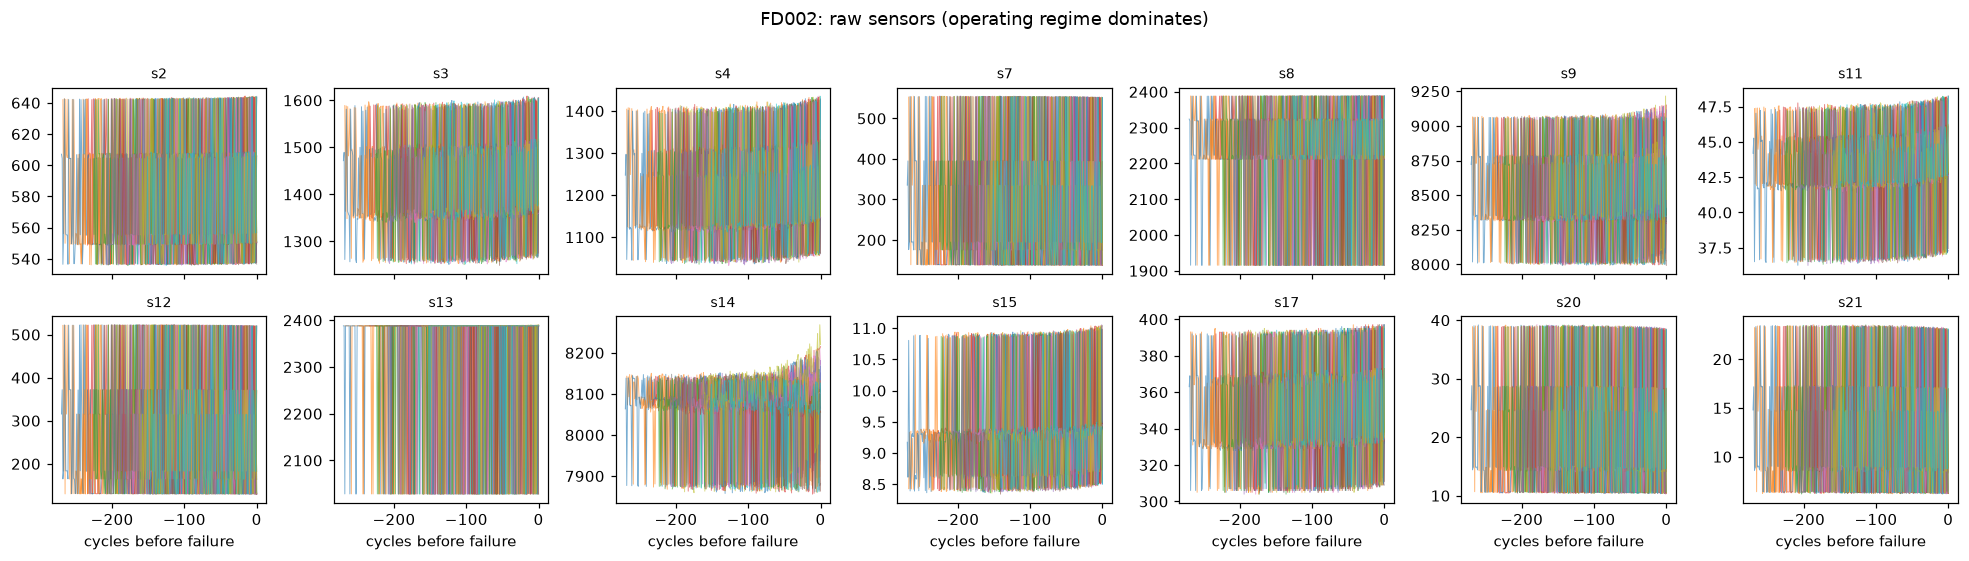

In [9]:
plot_trajectories("FD002", train["FD002"], "raw sensors (operating regime dominates)")

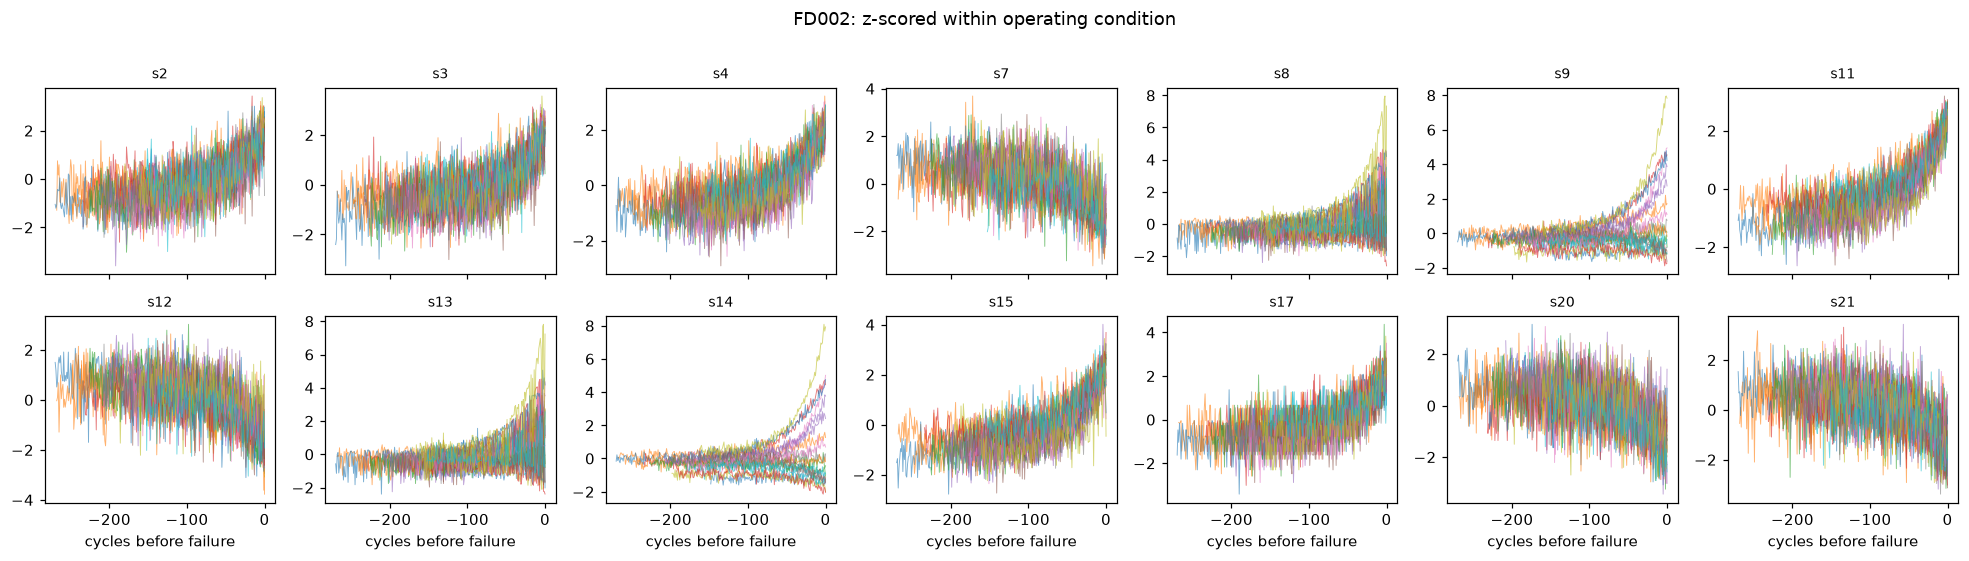

In [10]:
def condition_normalize(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    g = df.groupby("cond")[SENSORS]
    df[SENSORS] = (df[SENSORS] - g.transform("mean")) / (g.transform("std") + 1e-6)
    return df


plot_trajectories(
    "FD002", condition_normalize(train["FD002"]), "z-scored within operating condition"
)

Within-condition normalisation recovers the degradation trend in FD002 that is hidden
in the raw signal. HEPA's C-MAPSS path applies only a single *global* per-channel
z-score (`global_zscore_bundle`), which does not remove the regime effect; that is a
plausible reason FD002/FD004 sit at h-AUROC ~0.66/0.63 versus ~0.92/0.96 on FD001/FD003.

## 5. Sensor correlation with RUL

In [11]:
corr = pd.DataFrame({
    s: train[s][KEPT + ["rul"]].corr(method="spearman")["rul"].drop("rul") for s in SUBSETS
})
corr_cn = pd.DataFrame({
    s: condition_normalize(train[s])[KEPT + ["rul"]].corr(method="spearman")["rul"].drop("rul")
    for s in SUBSETS
})
pd.concat({"raw": corr, "condition-normalized": corr_cn}, axis=1).round(2)

raw                   condition-normalized                  
    FD001 FD002 FD003 FD004                FD001 FD002 FD003 FD004
s2  -0.63 -0.10 -0.65 -0.10                -0.63 -0.59 -0.65 -0.56
s3  -0.61 -0.12 -0.67 -0.13                -0.61 -0.57 -0.67 -0.62
s4  -0.70 -0.17 -0.73 -0.17                -0.70 -0.68 -0.73 -0.69
s7   0.68  0.08 -0.08 -0.02                 0.68  0.48 -0.08 -0.12
s8  -0.57 -0.06 -0.74 -0.09                -0.57 -0.38 -0.74 -0.53
s9  -0.32 -0.07 -0.59 -0.12                -0.32 -0.28 -0.59 -0.53
s11 -0.72 -0.17 -0.76 -0.18                -0.72 -0.71 -0.76 -0.73
s12  0.69  0.08 -0.09 -0.02                 0.69  0.50 -0.09 -0.13
s13 -0.57 -0.25 -0.74 -0.40                -0.57 -0.38 -0.74 -0.53
s14 -0.20 -0.07 -0.49 -0.17                -0.20 -0.16 -0.49 -0.43
s15 -0.67 -0.16 -0.09 -0.02                -0.67 -0.67 -0.09 -0.13
s17 -0.63 -0.12 -0.70 -0.13                -0.63 -0.60 -0.70 -0.64
s20  0.65  0.07  0.09  0.01                 0.65  0.45  0.09  0.07
s21  0.66  0.07  0.09  0.01                 0.66  0.45  0.09  0.07

In FD002/FD004 raw Spearman |rho| with RUL is mostly ~0.1-0.2; after within-condition
normalisation it rises to ~0.5-0.7, matching FD001/FD003. In FD003/FD004 (two fault
modes) s7, s12, s15, s20, s21 lose their RUL correlation, likely because the fan and
HPC faults push them in opposite directions and cancel out when pooled.

## 6. The event-prediction view HEPA trains on

`load_cmapss` splits train engines 60/10/30 by id. `EventDataset` emits a prediction
point at every cycle `t >= 128` (the minimum context), and `train.py` skips engines
with `<= 129` cycles. Horizon label: `y(t, h) = 1` if failure occurs within `h` cycles.

In [12]:
split_rows = []
for s in SUBSETS:
    b = load_cmapss(s)
    for split in ("ft_train", "ft_val", "ft_test"):
        ents = b[split]
        lens = np.array([len(e["test"]) for e in ents])
        used = lens > 129
        split_rows.append({
            "subset": s,
            "split": split,
            "engines": len(ents),
            "engines_used": int(used.sum()),
            "cycles_total": int(lens.sum()),
            "prediction_points": int(np.clip(lens[used] - 129, 0, None).sum()),
        })
splits = pd.DataFrame(split_rows).set_index(["subset", "split"])
splits["frac_engines_dropped"] = 1 - splits["engines_used"] / splits["engines"]
splits

engines  engines_used  cycles_total  prediction_points  frac_engines_dropped
subset split                                                                                 
FD001  ft_train       60            59         12310               4571              0.016667
       ft_val         10            10          2097                807              0.000000
       ft_test        30            30          6224               2354              0.000000
FD002  ft_train      156           155         31774              11650              0.006410
       ft_val         26            26          5749               2395              0.000000
       ft_test        78            77         16236               6175              0.012821
FD003  ft_train       60            60         14812               7072              0.000000
       ft_val         10            10          2594               1304              0.000000
       ft_test        30            30          7314               3444              0.000000
FD004  ft_train      149           148         36359              17139              0.006711
       ft_val         24            24          7105               4009              0.000000
       ft_test        76            76         17785               7981              0.000000

,FD001,FD002,FD003,FD004
h=1,0.013,0.012,0.009,0.010
h=10,0.126,0.125,0.087,0.095
h=50,0.571,0.564,0.406,0.445
h=100,0.885,0.873,0.646,0.738
h=150,0.980,0.979,0.783,0.902


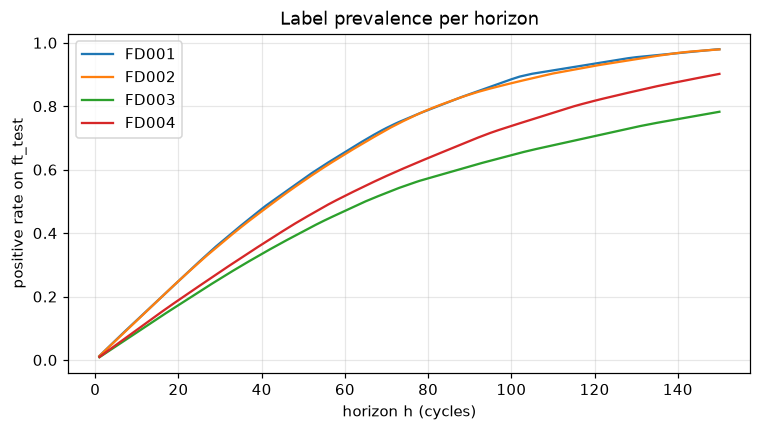

In [13]:
def horizon_prevalence(subset: str) -> np.ndarray:
    horizons = np.array(get_horizons(subset))
    b = load_cmapss(subset)
    ttes = []
    for e in b["ft_test"]:
        if len(e["test"]) <= 129:
            continue
        ds = EventDataset(
            e["test"], e["labels"], max_context=get_context(subset), stride=1,
            max_future=int(horizons.max()),
        )
        ttes.append(ds._tte[ds.starts])
    tte = np.concatenate(ttes)
    return (tte[:, None] <= horizons[None, :]).mean(axis=0)


fig, ax = plt.subplots(figsize=(8, 4))
prev = {}
for s in SUBSETS:
    prev[s] = horizon_prevalence(s)
    ax.plot(get_horizons(s), prev[s], label=s)
ax.set_xlabel("horizon h (cycles)")
ax.set_ylabel("positive rate on ft_test")
ax.set_title("Label prevalence per horizon")
ax.legend()
ax.grid(alpha=0.3)

pd.DataFrame({s: p[[0, 9, 49, 99, 149]] for s, p in prev.items()},
             index=["h=1", "h=10", "h=50", "h=100", "h=150"]).round(3)

Because prediction starts at cycle 128 and FD001 engines live a median ~200 cycles,
most evaluated points are already close to failure: the positive rate passes 50% around
h~43 and reaches ~98% at h=150. FD003/FD004 engines live longer, so their surfaces are
less saturated (~78% / ~90% at h=150). `REPRODUCIBILITY.md` flags this label surface
(1.3% at dt=1 here vs 0.5% in the paper) as the leading candidate for the gap to the
paper's FD001 number.